# IMDb sentiment classification

Which text representation and which model best predict whether a movie review is positive or negative, and how
sure can we be? This notebook runs the whole pipeline, top to bottom:

1. Data: load, clean, split
2. Tokeniser: BPE trained on unlabelled reviews
3. Representations: token indicator, bag-of-words, TF-IDF
4. Models: log-linear, MLP with one hidden layer, MLP with two hidden layers
5. Tuning on a dev set
6. Cross-validation: 5 folds × 3 seeds
7. Bayesian comparison against a ROPE, and selection
8. One final test evaluation
9. Error analysis

**Running it.** Slow stages (tuning, CV, test) save their results to `results/` and skip work already done, so a
run from the saved results takes a few minutes. Set `RECOMPUTE = True` to redo everything in a fresh folder,
`results_recomputed/`, which takes about 1.5 hours on a laptop CPU.

Helpers from the course tutorial (`SparseMLP`, the BPE trainer, the fold splitter and the Benavoli t-test wrapper)
are imported unchanged from `nlp1_tutorial/`. Everything else is defined here.

## Setup

In [1]:
import copy
import json
import re
import time
import warnings
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import torch
import torch.nn as nn
from datasets import load_dataset
from IPython.display import display
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from tokenizers import Tokenizer

from nlp1_tutorial import analysis, experiment, smlp

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="Creating a tensor from a list of numpy")  # raised inside smlp.py, harmless
warnings.filterwarnings("ignore", message="Sparse invariant checks")  # likewise

RECOMPUTE = False  # True: redo every stage into results_recomputed/ (about 1.5 hours on a laptop CPU)
RESULTS = Path("results_recomputed" if RECOMPUTE else "results")
FIGURES = RESULTS / "figures"
for folder in (RESULTS / "tokenizers", RESULTS / "cv_predictions", FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

SEEDS = [0, 3, 5]
NUM_FOLDS = 5
DEV_SIZE = 2500
ROPE = 0.005

In [2]:
REP_COLOR = {"indicator": "#2a78d6", "bow": "#eb6834", "tfidf": "#1baf7a"}
REP_MARKER = {"indicator": "o", "bow": "s", "tfidf": "D"}
REP_NAME = {"indicator": "Token indicator", "bow": "Bag-of-words", "tfidf": "TF-IDF"}
ARCH_NAME = {"logistic": "Log-linear", "mlp": "MLP (1 hidden)", "deep-mlp": "MLP (2 hidden)"}
ARCH_SHORT = {"logistic": "LL", "mlp": "MLP1", "deep-mlp": "MLP2"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

def label(system):
    arch, rep = system.split("_")
    return f"{ARCH_NAME[arch]} · {REP_NAME[rep]}"

## 1. Data

[`mteb/imdb`](https://huggingface.co/datasets/mteb/imdb) is a copy of the IMDb reviews of Maas et al. (2011). Labels are
0 (negative, rating ≤ 4) and 1 (positive, rating ≥ 7). This copy differs from the original release in two ways:

- It is already deduplicated, so train has 24,904 reviews and test 24,678, not 25,000 each, and the classes are only
  close to 50/50.
- The repository also has 50,000 unlabelled reviews (`unsupervised.jsonl`). The default config doesn't load them,
  so they are loaded separately. Some of them also appear in train or test, and those are removed.

**Cleaning:** `<br />` markup is replaced by spaces and the text is lowercased. Duplicates are checked again after cleaning.

**Splits:** a stratified **dev set** of 2,500 reviews is taken from train for tuning and early stopping. The rest of
train is the **CV pool**. Test is used once, at the end.

In [3]:
_LINE_BREAK = re.compile(r"<br\s*/?>", flags=re.IGNORECASE)
_WHITESPACE = re.compile(r"\s+")


def clean_text(text: str) -> str:
    """Drop the <br /> markup that fills IMDb reviews, normalise whitespace and lowercase."""
    return _WHITESPACE.sub(" ", _LINE_BREAK.sub(" ", text)).strip().lower()


@dataclass
class ImdbData:
    pool_texts: list  # cross-validation
    pool_labels: np.ndarray
    dev_texts: list  # tuning and early stopping
    dev_labels: np.ndarray
    test_texts: list  # used once, at the very end
    test_labels: np.ndarray
    unsup_texts: list  # tokeniser training only
    report: dict


def unique_cleaned(texts, labels):
    """Clean texts, then keep one copy of each. Texts seen with conflicting labels are dropped."""
    seen = {}
    for text, label in zip(texts, labels):
        seen.setdefault(clean_text(text), set()).add(label)
    kept = {text: next(iter(ls)) for text, ls in seen.items() if len(ls) == 1}
    return kept, len(seen) - len(kept)


def load_imdb(dev_size=DEV_SIZE, seed=0) -> ImdbData:
    ds = load_dataset("mteb/imdb")
    unsup = load_dataset("json", data_files="hf://datasets/mteb/imdb/unsupervised.jsonl", split="train")

    train, train_conflicts = unique_cleaned(ds["train"]["text"], ds["train"]["label"])
    test, test_conflicts = unique_cleaned(ds["test"]["text"], ds["test"]["label"])
    test_in_train = [t for t in test if t in train]
    for t in test_in_train:
        del test[t]

    # The tokeniser corpus must not contain any labelled review.
    unsup_all = {clean_text(t) for t in unsup["text"]}
    unsup_texts = sorted(unsup_all - train.keys() - test.keys())

    train_texts, train_labels = list(train), np.array(list(train.values()), dtype=np.int64)
    test_texts, test_labels = list(test), np.array(list(test.values()), dtype=np.int64)
    pool_ids, dev_ids = train_test_split(
        np.arange(len(train_texts)), test_size=dev_size, stratify=train_labels, random_state=seed
    )
    report = {
        "raw rows (train, test, unlabelled)": (len(ds["train"]), len(ds["test"]), len(unsup)),
        "after cleaning (train, test)": (len(train_texts), len(test_texts)),
        "conflicting labels (train, test)": (train_conflicts, test_conflicts),
        "test reviews also in train": len(test_in_train),
        "unlabelled: unique, after removing labelled": (len(unsup_all), len(unsup_texts)),
    }
    return ImdbData(
        pool_texts=[train_texts[i] for i in pool_ids], pool_labels=train_labels[pool_ids],
        dev_texts=[train_texts[i] for i in dev_ids], dev_labels=train_labels[dev_ids],
        test_texts=test_texts, test_labels=test_labels, unsup_texts=unsup_texts, report=report,
    )


data = load_imdb()
for key, value in data.report.items():
    print(f"{key}: {value}")
display(pd.DataFrame({
    "reviews": [len(data.pool_texts), len(data.dev_texts), len(data.test_texts), len(data.unsup_texts)],
    "positive rate": [data.pool_labels.mean(), data.dev_labels.mean(), data.test_labels.mean(), np.nan],
    "used for": ["cross-validation", "tuning, early stopping", "one final evaluation", "tokeniser training"],
}, index=["CV pool", "dev", "test", "unlabelled"]).round(4))
print(f"Majority-class baseline on test: {max(data.test_labels.mean(), 1 - data.test_labels.mean()):.4f}")

raw rows (train, test, unlabelled): (24904, 24678, 50000)
after cleaning (train, test): (24902, 24676)
conflicting labels (train, test): (0, 0)
test reviews also in train: 0
unlabelled: unique, after removing labelled: (49505, 48885)


,reviews,positive rate,used for
CV pool,22402,0.5008,cross-validation
dev,2500,0.5008,"tuning, early stopping"
test,24676,0.5030,one final evaluation
unlabelled,48885,NaN,tokeniser training


Majority-class baseline on test: 0.5030


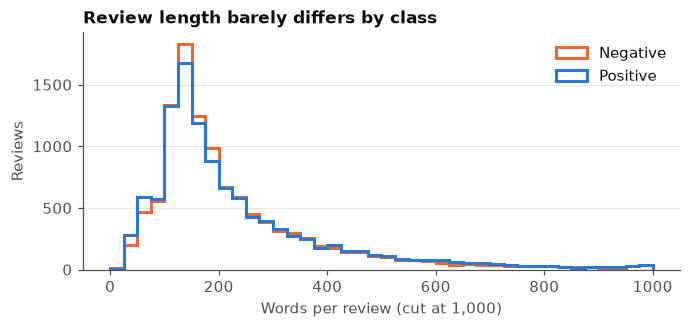

    mean    50%     max
0  228.9  173.0  1491.0
1  235.2  173.0  2459.0


In [4]:
lengths = np.array([len(t.split()) for t in data.pool_texts])
fig, ax = plt.subplots(figsize=(7, 2.8))
bins = np.arange(0, 1001, 25)
for value, name, color in [(0, "Negative", "#eb6834"), (1, "Positive", "#2a78d6")]:
    ax.hist(lengths[data.pool_labels == value], bins=bins, histtype="step", linewidth=2, color=color, label=name)
ax.set(xlabel="Words per review (cut at 1,000)", ylabel="Reviews", title="Review length barely differs by class")
ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True); ax.legend(frameon=False)
fig.savefig(FIGURES / "lengths.png"); plt.show()
print(pd.Series(lengths).groupby(data.pool_labels).describe()[["mean", "50%", "max"]].round(1))

## 2. Tokeniser

Byte-pair encoding, trained with the tutorial's `experiment.train_tokenizer` (Hugging Face `tokenizers`, Metaspace
pre-tokenisation, `min_frequency=2`).

**Training data:** the 48,885 unlabelled reviews. They are the same kind of text, there are plenty of them, and none
is in the labelled data, so the tokeniser cannot leak anything between folds and needs no refit per fold.

**Vocabulary size:** each candidate is scored with log-linear bag-of-words on dev, using the best of three values of
`C`. The rule is to take the smallest size within 0.005 of the best, which is the same size as the ROPE.

Each review is tokenised **once** into a sparse count matrix, and folds slice that matrix. The tutorial's encoders
re-tokenise every text for every fit, which is too slow for long reviews.

In [5]:
VOCAB_SIZES = (1000, 5000, 10000, 20000)
SWEEP_CS = (0.01, 0.1, 1.0)
MIN_FREQUENCY = 2
VOCAB_TOLERANCE = 0.005


def encode_counts(tokenizer, texts, chunk_size=2000) -> sp.csr_matrix:
    """Tokenise texts into a [num_texts, vocab_size] sparse matrix of token counts."""
    vocab_size = tokenizer.get_vocab_size()
    indptr, indices = [0], []
    for start in range(0, len(texts), chunk_size):
        for encoding in tokenizer.encode_batch_fast(texts[start:start + chunk_size]):
            indices.extend(encoding.ids)
            indptr.append(len(indices))
    counts = sp.csr_matrix(
        (np.ones(len(indices), dtype=np.float32), np.array(indices, dtype=np.int32), np.array(indptr)),
        shape=(len(texts), vocab_size),
    )
    counts.sum_duplicates()
    return counts


def fit_logistic(X, y, C=1.0, max_iter=2000):
    """Log-linear model (also one of the three architectures). Returns the model and whether it converged."""
    model = LogisticRegression(solver="lbfgs", C=C, max_iter=max_iter)
    model.fit(X, y)
    return model, bool(model.n_iter_[0] < max_iter)


def tokenizer_for(vocab_size):
    path = RESULTS / "tokenizers" / f"bpe_{vocab_size}.json"
    if not path.exists():
        experiment.train_tokenizer(data.unsup_texts, vocab_size, MIN_FREQUENCY).save(str(path))
    return Tokenizer.from_file(str(path))


sweep_path = RESULTS / "vocab_sweep.csv"
if not sweep_path.exists():
    rows = []
    for vocab_size in VOCAB_SIZES:
        tokenizer = tokenizer_for(vocab_size)
        pool, dev = encode_counts(tokenizer, data.pool_texts), encode_counts(tokenizer, data.dev_texts)
        for C in SWEEP_CS:
            model, converged = fit_logistic(pool, data.pool_labels, C=C)
            rows.append({"vocab_size": vocab_size, "C": C,
                         "dev_accuracy": accuracy_score(data.dev_labels, model.predict(dev)),
                         "mean_tokens_per_review": float(pool.sum(axis=1).mean()), "converged": converged})
    pd.DataFrame(rows).to_csv(sweep_path, index=False)
sweep = pd.read_csv(sweep_path)

best_per_size = sweep.loc[sweep.groupby("vocab_size")["dev_accuracy"].idxmax()].sort_values("vocab_size")
VOCAB_SIZE = int(best_per_size.loc[best_per_size["dev_accuracy"] >= best_per_size["dev_accuracy"].max() - VOCAB_TOLERANCE, "vocab_size"].min())
display(best_per_size[["vocab_size", "C", "dev_accuracy", "mean_tokens_per_review"]].round(4))
print("Chosen vocabulary size:", VOCAB_SIZE)

tokenizer = tokenizer_for(VOCAB_SIZE)
example = "this movie was not good, a disappointing waste of time but the acting is wonderful"
for size in (1000, VOCAB_SIZE):
    print(size, tokenizer_for(size).encode(example).tokens)

,vocab_size,C,dev_accuracy,mean_tokens_per_review
1,1000,0.10,0.8272,448.5876
3,5000,0.01,0.8716,319.7596
7,10000,0.10,0.8776,290.1877
10,20000,0.10,0.8792,269.9992


Chosen vocabulary size: 10000
1000 ['▁this', '▁movie', '▁was', '▁not', '▁good', ',', '▁a', '▁dis', 'app', 'o', 'int', 'ing', '▁was', 'te', '▁of', '▁time', '▁but', '▁the', '▁acting', '▁is', '▁wonder', 'ful']
10000 ['▁this', '▁movie', '▁was', '▁not', '▁good,', '▁a', '▁disappointing', '▁waste', '▁of', '▁time', '▁but', '▁the', '▁acting', '▁is', '▁wonderful']


In [6]:
pool_counts = encode_counts(tokenizer, data.pool_texts)
dev_counts = encode_counts(tokenizer, data.dev_texts)
test_counts = encode_counts(tokenizer, data.test_texts)  # encoded now, scored only once, in section 8
print("pool", pool_counts.shape, "dev", dev_counts.shape, "test", test_counts.shape)

pool (22402, 10000) dev (2500, 10000) test (24676, 10000)


## 3. Representations

| Representation | Feature for token *t* in review *x* |
|---|---|
| Token indicator | 1 if *t* occurs in *x*, else 0 |
| Bag-of-words | number of times *t* occurs in *x* |
| TF-IDF (our choice) | count × log inverse document frequency, then each review scaled to unit length |

TF-IDF down-weights tokens that appear everywhere ("movie", "the") and removes the effect of review length.
**The IDF weights are estimated on the training part of each fold only**, then applied to its validation part.

In [7]:
REPRESENTATIONS = ("indicator", "bow", "tfidf")


def to_representation(rep, X_fit, *others):
    """
    Turn count matrices into a representation. Anything estimated from data (the IDF weights)
    is estimated from X_fit alone, then applied to the other matrices. Returns one matrix per input.
    """
    matrices = (X_fit, *others)
    if rep == "indicator":
        return [(X > 0).astype(np.float32).tocsr() for X in matrices]
    if rep == "bow":
        return [X.astype(np.float32).tocsr() for X in matrices]
    if rep == "tfidf":
        tfidf = TfidfTransformer(norm="l2", use_idf=True).fit(X_fit)
        return [tfidf.transform(X).astype(np.float32).tocsr() for X in matrices]
    raise ValueError(f"Unknown representation: {rep}")

Checks that the splits and representations do what the text above claims:

In [8]:
pool_set, dev_set, test_set, unsup_set = map(set, (data.pool_texts, data.dev_texts, data.test_texts, data.unsup_texts))
assert len(pool_set) == len(data.pool_texts), "duplicates in the pool"
assert not (pool_set & dev_set or pool_set & test_set or dev_set & test_set), "overlap between labelled splits"
assert not unsup_set & (pool_set | dev_set | test_set), "labelled reviews in the tokeniser corpus"
assert not any("<br" in t for t in data.pool_texts), "markup left after cleaning"

ids = tokenizer.encode(data.pool_texts[0]).ids
assert pool_counts[0].sum() == len(ids) and pool_counts[0, ids[0]] == ids.count(ids[0]), "wrong token counts"
sample = pool_counts[:200]
indicator, bow, tfidf = (to_representation(rep, sample)[0] for rep in REPRESENTATIONS)
assert (indicator != (sample > 0)).nnz == 0, "indicator differs from counts > 0"
assert (bow != sample).nnz == 0, "bag-of-words differs from counts"
assert np.allclose(np.sqrt(tfidf.multiply(tfidf).sum(axis=1)), 1.0, atol=1e-5), "TF-IDF rows are not unit length"

# Shuffled labels must score at chance: anything higher means information is leaking.
n_train = int(0.8 * len(data.pool_texts))
shuffled = np.random.default_rng(0).permutation(data.pool_labels)
X_fit, X_held_out = to_representation("indicator", pool_counts[:n_train], pool_counts[n_train:])
model, _ = fit_logistic(X_fit, shuffled[:n_train])
print(f"All checks passed. Accuracy with shuffled labels: {accuracy_score(shuffled[n_train:], model.predict(X_held_out)):.4f} (chance is 0.5)")

All checks passed. Accuracy with shuffled labels: 0.5104 (chance is 0.5)


## 4. Models

| Architecture | What it is |
|---|---|
| Log-linear | Softmax regression (scikit-learn, L-BFGS). The tutorial's `saga` converges slowly on unscaled counts. |
| MLP (1 hidden) | The tutorial's `smlp.SparseMLP`: sparse input → hidden layer → ReLU → dropout → output |
| MLP (2 hidden), our choice | `SparseMLP` plus a second hidden layer of half the width, with heavier dropout |

MLPs train with AdamW, batch size 64, at most 30 epochs. **Early stopping uses the dev set**, keeping the epoch with the
lowest dev loss (patience 3). The tutorial instead picks the epoch on the fold it then reports, which makes MLP scores
look better than log-linear's.

In [9]:
ARCHITECTURES = ("logistic", "mlp", "deep-mlp")
SYSTEMS = tuple(f"{arch}_{rep}" for arch in ARCHITECTURES for rep in REPRESENTATIONS)  # simplest first


class DeepSparseMLP(smlp.SparseMLP):
    """SparseMLP with a second hidden layer, half the width of the first."""

    def __init__(self, input_dim, hidden_dim, num_classes, dropout=0.5):
        super().__init__(input_dim, hidden_dim, num_classes, dropout)
        second_dim = max(hidden_dim // 2, 1)
        self.hidden2 = nn.Sequential(nn.Linear(hidden_dim, second_dim), nn.ReLU(), nn.Dropout(dropout))
        self.output = nn.Sequential(nn.Linear(second_dim, num_classes), nn.LogSoftmax(dim=-1))

    def forward(self, x):
        x = torch.sparse.mm(x, self.weight) + self.bias
        x = self.dropout(self.activation(x))
        return self.output(self.hidden2(x))


class SparseBatches:
    """
    Yields (sparse X batch, y batch) as smlp.train_one_epoch and smlp.evaluate expect.
    Slicing the CSR matrix once per batch is much faster than smlp.SparseDataset's per-row slicing.
    """

    def __init__(self, X, y, batch_size, shuffle=False, seed=0):
        self.X, self.y = X.tocsr(), torch.as_tensor(y, dtype=torch.long)
        self.batch_size, self.shuffle = batch_size, shuffle
        self.generator = torch.Generator().manual_seed(seed)

    def __iter__(self):
        n = self.X.shape[0]
        order = torch.randperm(n, generator=self.generator) if self.shuffle else torch.arange(n)
        for start in range(0, n, self.batch_size):
            ids = order[start:start + self.batch_size]
            yield smlp.scipy_to_torch_sparse(self.X[ids.numpy()]), self.y[ids]


def fit_mlp(X_train, y_train, X_dev, y_dev, deep=False, hidden_dim=128, dropout=0.1, learning_rate=1e-3,
            weight_decay=1e-4, batch_size=64, max_epochs=30, patience=3, seed=0, num_classes=2):
    """Train with early stopping on dev. Returns the model at its best dev-loss epoch and training info."""
    torch.manual_seed(seed)
    model_class = DeepSparseMLP if deep else smlp.SparseMLP
    model = model_class(input_dim=X_train.shape[1], hidden_dim=hidden_dim, num_classes=num_classes, dropout=dropout)
    criterion = nn.NLLLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    train_batches = SparseBatches(X_train, y_train, batch_size, shuffle=True, seed=seed)
    dev_batches = SparseBatches(X_dev, y_dev, 512)

    history, best_state, best_loss, best_epoch = [], None, float("inf"), -1
    for epoch in range(max_epochs):
        train_metrics = smlp.train_one_epoch(model, train_batches, optimizer, criterion)
        dev_metrics, _ = smlp.evaluate(model, dev_batches, criterion)
        history.append({"epoch": epoch, "train": train_metrics, "dev": dev_metrics})
        if dev_metrics["loss"] < best_loss:
            best_loss, best_epoch = dev_metrics["loss"], epoch
            best_state = copy.deepcopy(model.state_dict())
        elif epoch - best_epoch >= patience:
            break
    model.load_state_dict(best_state)
    return model, {"history": history, "best_epoch": best_epoch, "best_dev_loss": best_loss}


def predict(model, X):
    """Predicted labels for any of the models."""
    if not isinstance(model, nn.Module):
        return model.predict(X)
    _, predictions = smlp.evaluate(model, SparseBatches(X, np.zeros(X.shape[0], dtype=np.int64), 512), nn.NLLLoss())
    return predictions


def fit_system(system, params, X_train_counts, y_train, X_dev_counts, y_dev, seed=0):
    """
    Fit one system from count matrices.
    Returns (model, a function mapping counts to this system's features, info).
    """
    arch, rep = system.split("_")
    start = time.time()
    X_train, X_dev = to_representation(rep, X_train_counts, X_dev_counts)  # dev never shapes the IDF

    def featurize(counts):
        return to_representation(rep, X_train_counts, counts)[1]

    if arch == "logistic":
        model, converged = fit_logistic(X_train, y_train, **params)
        info = {"converged": converged}
    else:
        model, details = fit_mlp(X_train, y_train, X_dev, y_dev, deep=arch == "deep-mlp", seed=seed, **params)
        info = {"converged": True, "best_epoch": details["best_epoch"], "best_dev_loss": details["best_dev_loss"]}
    info["fit_seconds"] = time.time() - start
    return model, featurize, info


def scores(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred), "macro_f1": f1_score(y_true, y_pred, average="macro")}

## 5. Tuning on dev

Each system gets a small grid. Models train on the whole CV pool and are scored on dev, and the setting with the best dev
accuracy is kept. Every system is tuned, because comparing a tuned system with an untuned one would not be fair.

The first grids put several choices at their edges: `C = 10` for log-linear TF-IDF, and the lowest learning rate for
every MLP. They were extended with `C = 100` and a learning rate of `3e-5`. The two learning-rate edge picks that remain
gain at most 0.002 on dev, which is within its standard error of about 0.0065. Every grid offers only two widths and two
dropout values, so some choices are always at an edge.

In [10]:
def param_grid(system):
    arch, _ = system.split("_")
    if arch == "logistic":
        return [{"C": c} for c in (0.01, 0.1, 1.0, 10.0, 100.0)]
    dropouts = (0.1, 0.5) if arch == "mlp" else (0.5, 0.7)
    return [{"hidden_dim": h, "dropout": d, "learning_rate": lr}
            for h in (128, 256) for d in dropouts for lr in (1e-3, 1e-4, 3e-5)]


def append_row(path, row):
    pd.DataFrame([row]).to_csv(path, mode="a", header=not path.exists(), index=False)


def run_tuning(systems, path):
    """Grid search per system. Skips settings already in the file, so an interrupted run resumes."""
    done = set()
    if path.exists():
        done = {(r["system"], r["params"]) for _, r in pd.read_csv(path, dtype=str).iterrows()}
    for system in systems:
        for params in param_grid(system):
            key = json.dumps(params, sort_keys=True)
            if (system, key) in done:
                continue
            model, featurize, info = fit_system(system, params, pool_counts, data.pool_labels, dev_counts, data.dev_labels)
            accuracy = accuracy_score(data.dev_labels, predict(model, featurize(dev_counts)))
            append_row(path, {"system": system, "params": key, "dev_accuracy": accuracy, "converged": info["converged"],
                              "best_epoch": info.get("best_epoch", ""), "fit_seconds": round(info["fit_seconds"], 1)})
            print(f"{system} {key} dev accuracy {accuracy:.4f} ({info['fit_seconds']:.0f}s)")
    return pd.read_csv(path)


def best_params(tuning):
    """Per system, the setting with the best dev accuracy (ties go to the earlier grid entry)."""
    chosen = tuning.loc[tuning.groupby("system")["dev_accuracy"].idxmax()]
    return {row["system"]: json.loads(row["params"]) for _, row in chosen.iterrows()}


tuning = run_tuning(SYSTEMS, RESULTS / "tuning.csv")
PARAMS = best_params(tuning)
chosen = tuning.loc[tuning.groupby("system")["dev_accuracy"].idxmax()].set_index("system").reindex(list(SYSTEMS))
display(chosen[["params", "dev_accuracy", "best_epoch"]])
print(f"{len(tuning)} tuning fits, {tuning['fit_seconds'].sum() / 60:.0f} minutes of fitting; all converged: {tuning['converged'].all()}")

,params,dev_accuracy,best_epoch
system,,,
logistic_indicator,"{""C"": 0.1}",0.8756,NaN
logistic_bow,"{""C"": 0.1}",0.8776,NaN
logistic_tfidf,"{""C"": 10.0}",0.8820,NaN
mlp_indicator,"{""dropout"": 0.5, ""hidden_dim"": 128, ""learning_...",0.8904,4.0
mlp_bow,"{""dropout"": 0.1, ""hidden_dim"": 256, ""learning_...",0.8900,8.0
mlp_tfidf,"{""dropout"": 0.1, ""hidden_dim"": 256, ""learning_...",0.8956,6.0
deep-mlp_indicator,"{""dropout"": 0.7, ""hidden_dim"": 256, ""learning_...",0.8932,12.0
deep-mlp_bow,"{""dropout"": 0.5, ""hidden_dim"": 256, ""learning_...",0.8900,3.0
deep-mlp_tfidf,"{""dropout"": 0.7, ""hidden_dim"": 256, ""learning_...",0.8972,4.0


87 tuning fits, 35 minutes of fitting; all converged: True


## 6. Cross-validation

The tutorial's `experiment.cross_validation_split` makes 5 folds for each of 3 seeds (0, 3, 5). That gives 15
validation scores per system, paired across systems because every system sees the same folds. For each fold:

1. Build the representation from the training part (TF-IDF's IDF included).
2. Fit with the tuned settings, seeding torch with `seed × 1000 + fold`.
3. Score on the validation part.

In [11]:
def fold_ids(seed):
    """Training and validation row ids of each fold, from the tutorial's splitter."""
    folds = experiment.cross_validation_split(list(zip(data.pool_texts, data.pool_labels)), k=NUM_FOLDS, seed=seed)
    return {f: (np.array(fold["training_ids"], dtype=int), np.array(fold["validation_ids"], dtype=int)) for f, fold in folds.items()}


def run_cv(systems, path, params):
    """Cross-validate systems. Skips (system, seed, fold) already in the file, so an interrupted run resumes."""
    done = set()
    if path.exists():
        done = {(r.system, int(r.seed), int(r.fold)) for r in pd.read_csv(path).itertuples()}
    for seed in SEEDS:
        for fold, (train_ids, val_ids) in fold_ids(seed).items():
            for system in systems:
                if (system, seed, fold) in done:
                    continue
                model, featurize, info = fit_system(system, params[system], pool_counts[train_ids], data.pool_labels[train_ids],
                                                    dev_counts, data.dev_labels, seed=seed * 1000 + fold)
                predictions = predict(model, featurize(pool_counts[val_ids]))
                np.savez_compressed(RESULTS / "cv_predictions" / f"{system}_s{seed}_f{fold}.npz", ids=val_ids, predictions=predictions)
                result = scores(data.pool_labels[val_ids], predictions)
                append_row(path, {"system": system, "seed": seed, "fold": fold, **result, "converged": info["converged"],
                                  "best_epoch": info.get("best_epoch", ""), "fit_seconds": round(info["fit_seconds"], 1)})
                print(f"{system} seed {seed} fold {fold}: accuracy {result['accuracy']:.4f} ({info['fit_seconds']:.0f}s)")
    return pd.read_csv(path)


cv = run_cv(SYSTEMS, RESULTS / "cv_scores.csv", PARAMS)
assert (cv.groupby("system").size() == len(SEEDS) * NUM_FOLDS).all() and cv["converged"].all()
table = cv.groupby("system").agg(accuracy=("accuracy", "mean"), sd=("accuracy", "std"), macro_f1=("macro_f1", "mean"),
                                 fit_seconds=("fit_seconds", "mean")).reindex(list(SYSTEMS))
display(table.round(4))

,accuracy,sd,macro_f1,fit_seconds
system,,,,
logistic_indicator,0.8714,0.0050,0.8713,0.4267
logistic_bow,0.8723,0.0051,0.8723,1.8867
logistic_tfidf,0.8813,0.0053,0.8812,0.4400
mlp_indicator,0.8846,0.0046,0.8846,15.6933
mlp_bow,0.8885,0.0046,0.8885,33.8533
mlp_tfidf,0.8913,0.0036,0.8913,29.2400
deep-mlp_indicator,0.8839,0.0048,0.8839,45.2867
deep-mlp_bow,0.8874,0.0049,0.8874,18.3667
deep-mlp_tfidf,0.8911,0.0045,0.8911,23.2467


**Reproducibility:** refitting one stored fold must give exactly the same predictions.

In [12]:
train_ids, val_ids = fold_ids(3)[1]
for system in ("logistic_tfidf", "mlp_tfidf"):
    model, featurize, _ = fit_system(system, PARAMS[system], pool_counts[train_ids], data.pool_labels[train_ids],
                                     dev_counts, data.dev_labels, seed=3 * 1000 + 1)
    stored = np.load(RESULTS / "cv_predictions" / f"{system}_s3_f1.npz")
    same = (stored["ids"] == val_ids).all() and (stored["predictions"] == predict(model, featurize(pool_counts[val_ids]))).all()
    print(f"{system}, seed 3, fold 1: identical predictions = {same}")

logistic_tfidf, seed 3, fold 1: identical predictions = True


mlp_tfidf, seed 3, fold 1: identical predictions = True


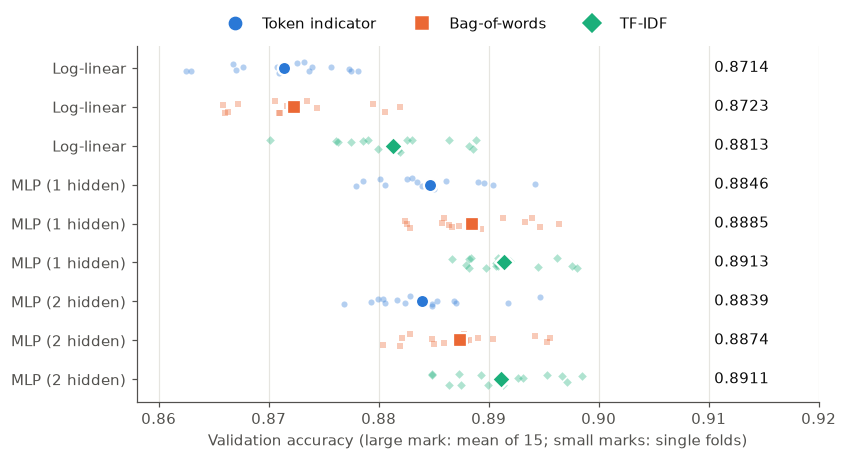

In [13]:
classifier_data = analysis.make_data_frame({
    system: [{"accuracies": dict(zip(run["fold"], run["accuracy"]))} for _, run in cv[cv["system"] == system].sort_values("fold").groupby("seed")]
    for system in SYSTEMS
})
fig, ax = plt.subplots(figsize=(8, 4.2))
rng = np.random.default_rng(0)
order = list(SYSTEMS)[::-1]
for y, system in enumerate(order):
    rep = system.split("_")[1]
    values = classifier_data.loc[classifier_data["model"] == system, "accuracy"]
    ax.scatter(values, y + rng.uniform(-0.16, 0.16, len(values)), s=16, alpha=0.35, color=REP_COLOR[rep], marker=REP_MARKER[rep], linewidths=0)
    ax.scatter(values.mean(), y, s=75, color=REP_COLOR[rep], marker=REP_MARKER[rep], edgecolors="white", linewidths=1.5, zorder=3)
    ax.text(0.9105, y, f"{values.mean():.4f}", va="center", ha="left", color=INK)
ax.set_yticks(range(len(order)), [ARCH_NAME[s.split("_")[0]] for s in order])
ax.set_xlim(0.858, 0.92); ax.set_xlabel("Validation accuracy (large mark: mean of 15; small marks: single folds)")
ax.xaxis.grid(True, color=GRID); ax.set_axisbelow(True)
handles = [plt.Line2D([], [], linestyle="", marker=REP_MARKER[r], color=REP_COLOR[r], markersize=8, label=REP_NAME[r]) for r in REPRESENTATIONS]
ax.legend(handles=handles, frameon=False, ncols=3, loc="lower center", bbox_to_anchor=(0.45, 1.0))
fig.savefig(FIGURES / "cv_accuracy.png"); plt.show()

## 7. Bayesian comparison and selection

For each pair of systems, the correlated Bayesian t-test (Benavoli et al. 2017; the tutorial's
`analysis.BenavoliCorrelatedT`) gives a posterior over the mean accuracy difference B − A. **`runs=3` must be passed**:
the Nadeau-Bengio variance correction needs the number of folds per run (5), not the total number of scores (15).
The tutorial's example omits it because it used one seed.

**ROPE = 0.005.** This is 5 reviews in 1,000, about one standard error of one fold's accuracy
(√(0.88 × 0.12 / 4,480) ≈ 0.0049). The fold-to-fold SD in the table above is the same size.

In [14]:
def paired_scores(df, system, metric="accuracy"):
    """Scores in (seed, fold) order, so they pair up across systems."""
    return df[df["system"] == system].sort_values(["seed", "fold"])[metric].to_numpy()


def compare_pair(df, system_a, system_b, metric="accuracy"):
    return analysis.BenavoliCorrelatedT(paired_scores(df, system_a, metric), paired_scores(df, system_b, metric),
                                        runs=df["seed"].nunique(), names=[system_a, system_b])


# Check the library against the formula by hand, for one pair
a, b = paired_scores(cv, "logistic_tfidf"), paired_scores(cv, "mlp_tfidf")
diff, n = b - a, len(b)
by_hand = diff.var(ddof=1) * (1 / n + 1 / (n / len(SEEDS) - 1))
posterior = compare_pair(cv, "logistic_tfidf", "mlp_tfidf")
assert np.isclose(diff.mean(), posterior.mean_diff) and np.isclose(by_hand, posterior.std ** 2) and posterior.df == n - 1


def contrasts(df, pairs, rope=ROPE):
    rows = []
    for a, b in pairs:
        posterior = compare_pair(df, a, b)
        p_a, p_tie, p_b = posterior.probs(rope)
        rows.append({"A": label(a), "B": label(b), "mean B-A": posterior.mean_diff, "P(A wins)": p_a, "P(tie)": p_tie, "P(B wins)": p_b})
    return pd.DataFrame(rows).round(4)


print("Architecture, within each representation")
display(contrasts(cv, [(f"logistic_{r}", f"mlp_{r}") for r in REPRESENTATIONS] + [(f"mlp_{r}", f"deep-mlp_{r}") for r in REPRESENTATIONS]))
print("Representation, within each architecture")
display(contrasts(cv, [(f"{a}_indicator", f"{a}_bow") for a in ARCHITECTURES] + [(f"{a}_bow", f"{a}_tfidf") for a in ARCHITECTURES]))

Architecture, within each representation


,A,B,mean B-A,P(A wins),P(tie),P(B wins)
0,Log-linear · Token indicator,MLP (1 hidden) · Token indicator,0.0133,0.0000,0.0002,0.9998
1,Log-linear · Bag-of-words,MLP (1 hidden) · Bag-of-words,0.0162,0.0000,0.0000,1.0000
2,Log-linear · TF-IDF,MLP (1 hidden) · TF-IDF,0.0101,0.0000,0.0025,0.9975
3,MLP (1 hidden) · Token indicator,MLP (2 hidden) · Token indicator,-0.0007,0.0046,0.9948,0.0006
4,MLP (1 hidden) · Bag-of-words,MLP (2 hidden) · Bag-of-words,-0.0011,0.0160,0.9827,0.0013
5,MLP (1 hidden) · TF-IDF,MLP (2 hidden) · TF-IDF,-0.0003,0.0013,0.9981,0.0006


Representation, within each architecture


,A,B,mean B-A,P(A wins),P(tie),P(B wins)
0,Log-linear · Token indicator,Log-linear · Bag-of-words,0.0009,0.0027,0.9771,0.0201
1,MLP (1 hidden) · Token indicator,MLP (1 hidden) · Bag-of-words,0.0039,0.0002,0.7226,0.2773
2,MLP (2 hidden) · Token indicator,MLP (2 hidden) · Bag-of-words,0.0035,0.0000,0.8300,0.1700
3,Log-linear · Bag-of-words,Log-linear · TF-IDF,0.0090,0.0000,0.0035,0.9965
4,MLP (1 hidden) · Bag-of-words,MLP (1 hidden) · TF-IDF,0.0029,0.0000,0.9724,0.0276
5,MLP (2 hidden) · Bag-of-words,MLP (2 hidden) · TF-IDF,0.0036,0.0011,0.7159,0.2831


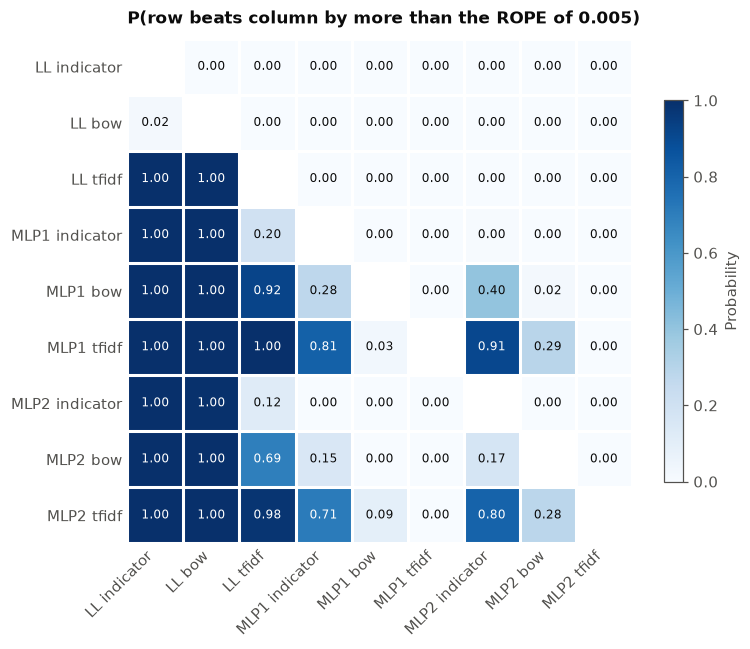

In [15]:
def win_matrix(df, systems, rope=ROPE):
    """matrix[i, j] = P(system i beats system j by more than the ROPE)."""
    matrix = np.full((len(systems), len(systems)), np.nan)
    for i, a in enumerate(systems):
        for j, b in enumerate(systems[i + 1:], start=i + 1):
            p_a, _, p_b = compare_pair(df, a, b).probs(rope)
            matrix[i, j], matrix[j, i] = p_a, p_b
    return matrix


systems = list(SYSTEMS)
matrix = win_matrix(cv, systems)
pd.DataFrame(matrix, index=systems, columns=systems).to_csv(RESULTS / "win_probabilities.csv")
fig, ax = plt.subplots(figsize=(7.4, 6))
image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
short = [f"{ARCH_SHORT[s.split('_')[0]]} {s.split('_')[1]}" for s in systems]
ax.set_xticks(range(len(systems)), short, rotation=45, ha="right"); ax.set_yticks(range(len(systems)), short)
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_xticks(np.arange(-.5, len(systems)), minor=True); ax.set_yticks(np.arange(-.5, len(systems)), minor=True)
ax.grid(which="minor", color="white", linewidth=2); ax.tick_params(which="minor", length=0)
for i in range(len(systems)):
    for j in range(len(systems)):
        if i != j:
            ax.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if matrix[i, j] > 0.6 else INK)
ax.set_title(f"P(row beats column by more than the ROPE of {ROPE})", pad=10)
fig.colorbar(image, ax=ax, shrink=0.75, label="Probability")
fig.savefig(FIGURES / "pairwise_heatmap.png"); plt.show()

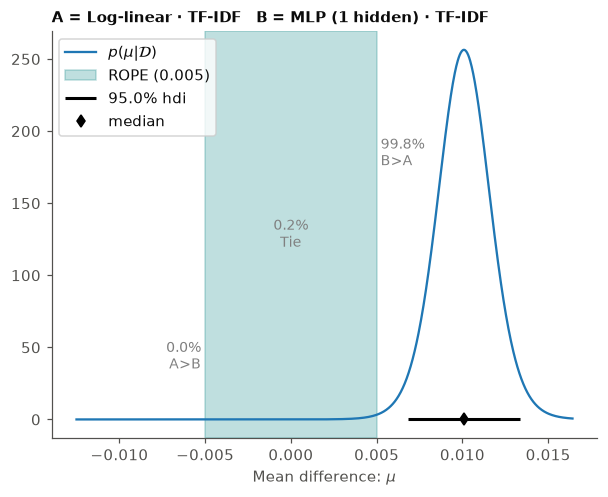

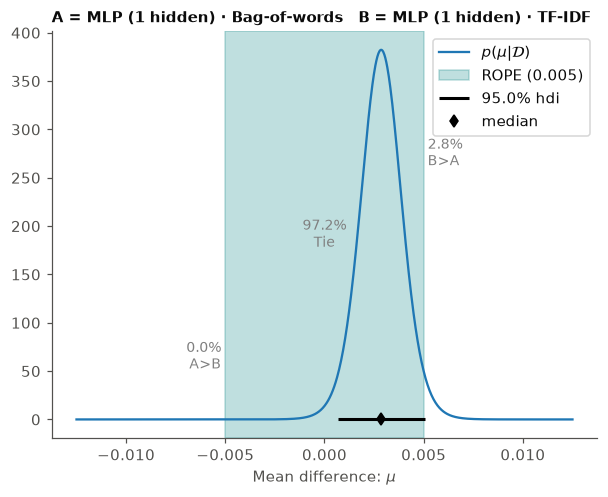

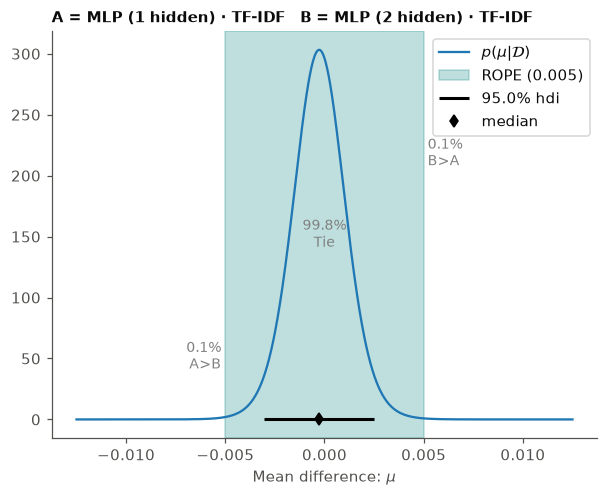

In [16]:
for a, b in [("logistic_tfidf", "mlp_tfidf"), ("mlp_bow", "mlp_tfidf"), ("mlp_tfidf", "deep-mlp_tfidf")]:
    fig, ax = compare_pair(cv, a, b).plot(ROPE)
    ax.set_title(f"A = {label(a)}   B = {label(b)}", fontsize=10)
    fig.savefig(FIGURES / f"posterior_{a}_vs_{b}.png"); plt.show()

**Selection rule**, fixed before the results were seen: take the simplest system that the top scorer does not beat by
more than the ROPE with probability ≥ 0.5. "Simplest" follows the order of `SYSTEMS`: log-linear before the MLPs, and
indicator, bag-of-words, TF-IDF within each.

The architecture conclusion holds at every ROPE tried, but **which representation is selected depends on the ROPE**.

In [17]:
def select_system(df, rope=ROPE, metric="accuracy", max_p_worse=0.5):
    """Returns (selected system, top-scoring system)."""
    means = df.groupby("system")[metric].mean()
    best = means.idxmax()
    for system in SYSTEMS:
        if system == best:
            break
        _, _, p_best_wins = compare_pair(df, system, best, metric).probs(rope)
        if p_best_wins < max_p_worse:
            return system, best
    return best, best


rows = []
for rope in (0.0025, 0.005, 0.01):
    selected, best = select_system(cv, rope=rope)
    p = compare_pair(cv, selected, best).probs(rope)[2] if selected != best else np.nan
    rows.append({"ROPE": rope, "selected": selected, "top scorer": best, "P(top scorer wins)": p})
display(pd.DataFrame(rows).round(4))
SELECTED, TOP = select_system(cv)
print(f"Selected at ROPE {ROPE}: {SELECTED}. Selected using macro-F1: {select_system(cv, metric='macro_f1')[0]}")

,ROPE,selected,top scorer,P(top scorer wins)
0,0.0025,mlp_tfidf,mlp_tfidf,NaN
1,0.0050,mlp_bow,mlp_tfidf,0.0276
2,0.0100,mlp_indicator,mlp_tfidf,0.0509


Selected at ROPE 0.005: mlp_bow. Selected using macro-F1: mlp_bow


## 8. Final test evaluation

Only the selected system is evaluated, once. Its 15 fold models are refitted with the same seeds and scored on test,
individually and as a majority vote. Each model trains on 4/5 of the pool and stops early on dev.

In [18]:
test_path, votes_path = RESULTS / "test_results.json", RESULTS / "test_predictions.npz"
if not (test_path.exists() and votes_path.exists()):
    single, votes = [], []
    for seed in SEEDS:
        for fold, (train_ids, _) in fold_ids(seed).items():
            model, featurize, _ = fit_system(SELECTED, PARAMS[SELECTED], pool_counts[train_ids], data.pool_labels[train_ids],
                                             dev_counts, data.dev_labels, seed=seed * 1000 + fold)
            votes.append(predict(model, featurize(test_counts)))
            single.append(accuracy_score(data.test_labels, votes[-1]))
            print(f"seed {seed} fold {fold}: test accuracy {single[-1]:.4f}")
    votes = np.stack(votes)
    majority = (votes.mean(axis=0) > 0.5).astype(np.int64)  # an odd number of voters, so no ties
    np.savez_compressed(votes_path, majority=majority, votes=votes, labels=data.test_labels)
    test_path.write_text(json.dumps({
        "system": SELECTED, "params": PARAMS[SELECTED], "num_models": len(single),
        "single_model_accuracy_mean": float(np.mean(single)), "single_model_accuracy_std": float(np.std(single, ddof=1)),
        "majority_vote": scores(data.test_labels, majority),
    }, indent=2))

test_results = json.loads(test_path.read_text())
assert test_results["system"] == SELECTED, "saved test results belong to a different system"
saved = np.load(votes_path)
votes, majority, gold = saved["votes"], saved["majority"], saved["labels"]
assert (gold == data.test_labels).all()

cv_accuracy = cv.loc[cv["system"] == SELECTED, "accuracy"].mean()
single = test_results["single_model_accuracy_mean"]
display(pd.DataFrame({"accuracy": [cv_accuracy, single, test_results["majority_vote"]["accuracy"]]},
                     index=["CV, mean of 15 folds", "test, single model (mean of 15)", "test, majority vote of 15"]).round(4))
print(f"CV to test gap for single models: {cv_accuracy - single:.4f} (test standard error about {np.sqrt(single * (1 - single) / len(gold)):.4f})")
print(classification_report(gold, majority, target_names=["negative", "positive"], digits=4))
print(pd.DataFrame(confusion_matrix(gold, majority), index=["true neg", "true pos"], columns=["pred neg", "pred pos"]))

,accuracy
"CV, mean of 15 folds",0.8885
"test, single model (mean of 15)",0.8803
"test, majority vote of 15",0.8853


CV to test gap for single models: 0.0082 (test standard error about 0.0021)
              precision    recall  f1-score   support

    negative     0.8851    0.8840    0.8846     12265
    positive     0.8855    0.8866    0.8861     12411

    accuracy                         0.8853     24676
   macro avg     0.8853    0.8853    0.8853     24676
weighted avg     0.8853    0.8853    0.8853     24676

          pred neg  pred pos
true neg     10842      1423
true pos      1407     11004


Single models lose about 0.008 from CV to test, roughly four test standard errors. One hypothesis is **movie overlap**:
the IMDb authors keep train and test movies disjoint, while random folds can put reviews of the same movie on both sides.
This copy has no movie IDs, so the hypothesis is **untested**. The weights in section 9 contain almost no names, which is
weak evidence against it.

## 9. Error analysis

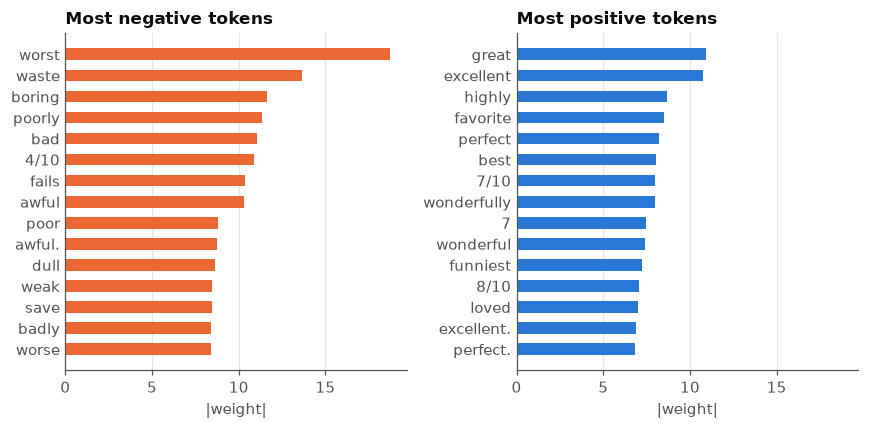

Weights from log-linear TF-IDF refitted on the whole pool. They illustrate the features; they do not explain the selected MLP.
Top 150 tokens by |weight|: worst, waste, boring, poorly, bad, great, 4/10, excellent, fails, awful, poor, awful., highly, dull, favorite, weak, save, badly, worse, supposed, perfect, terrible., nothing, best, 7/10, wonderfully, disappointing, lame, lacks, unless, annoying, horrible, 7, unfortunately,, wonderful, funniest, disappointment, 8/10, loved, pointless, excellent., perfect., stupid, ridiculous, amazing, disappointment., bit, superb, rare, no, 8, basically, well, okay, well., boring., refreshing, enjoyable, avoid, hilarious, mediocre, stink, looks, surprisingly, 3/10, fun, terrible, embarrass, enjoyed, entertaining, definitely, boring,, awful,, insult, true, subtle, wonder, hack, liked, tight, tedious, brain, bored, cheap, brilliant., solid, tries, delightful, mess., unconvincing, redeeming, script, touching, powerful, bad,, bad., instead, amazing., oh,

In [19]:
X_pool = to_representation("tfidf", pool_counts)[0]
linear, _ = fit_logistic(X_pool, data.pool_labels, **PARAMS["logistic_tfidf"])
id_to_token = {i: t.replace("▁", " ").strip() + ("" if t.startswith("▁") else " (suffix)") for t, i in tokenizer.get_vocab().items()}
weights = linear.coef_[0]
top = 15
fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharex=True)
for ax, ids, color, title in [
    (axes[0], np.argsort(weights)[:top], "#eb6834", "Most negative tokens"),
    (axes[1], np.argsort(weights)[-top:][::-1], "#2a78d6", "Most positive tokens"),
]:
    ax.barh(range(top), np.abs(weights[ids]), color=color, height=0.55)
    ax.set_yticks(range(top), [id_to_token[i] for i in ids]); ax.invert_yaxis()
    ax.set_title(title); ax.set_xlabel("|weight|"); ax.xaxis.grid(True, color=GRID); ax.set_axisbelow(True); ax.tick_params(axis="y", length=0)
fig.tight_layout(); fig.savefig(FIGURES / "top_weights.png"); plt.show()
print("Weights from log-linear TF-IDF refitted on the whole pool. They illustrate the features; they do not explain the selected MLP.")
print("Top 150 tokens by |weight|:", ", ".join(id_to_token[i] for i in np.argsort(-np.abs(weights))[:150]))

### Reviewers often state their rating

Tokens like `4/10`, `7/10` and `8/10` carry large weights. Labels come from each review's rating, so a rating written in
the text nearly gives the answer. It is real text and available at prediction time, but it makes the task easier than
judging sentiment from the prose.

In [20]:
rating = re.compile(r"\b\d{1,2}(?:\.\d)?\s?(?:/|out of)\s?10\b")
has_rating = np.array([bool(rating.search(t)) for t in data.test_texts])
correct = majority == gold
display(pd.DataFrame({
    "reviews": [has_rating.sum(), (~has_rating).sum()],
    "share": [has_rating.mean(), (~has_rating).mean()],
    "accuracy": [correct[has_rating].mean(), correct[~has_rating].mean()],
}, index=["states a rating out of 10", "does not"]).round(4))

,reviews,share,accuracy
states a rating out of 10,2176,0.0882,0.9118
does not,22500,0.9118,0.8828


,mean,size,se
group,,,
"(3.999, 117.0]",0.8912,4998,0.0044
"(117.0, 149.0]",0.8943,4956,0.0044
"(149.0, 200.0]",0.8824,4896,0.0046
"(200.0, 310.0]",0.8817,4895,0.0046
"(310.0, 2235.0]",0.8769,4931,0.0047


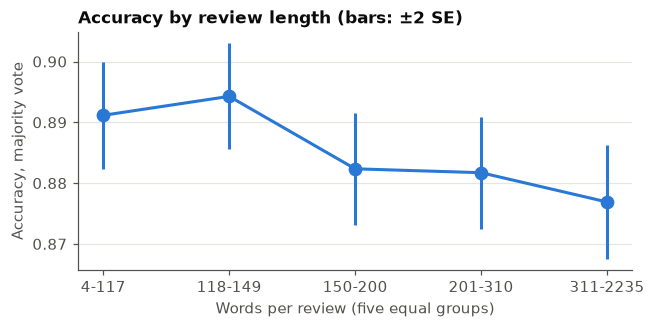

In [21]:
test_lengths = np.array([len(t.split()) for t in data.test_texts])
by_length = pd.DataFrame({"correct": correct, "group": pd.qcut(test_lengths, 5)}).groupby("group", observed=True)["correct"].agg(["mean", "size"])
by_length["se"] = np.sqrt(by_length["mean"] * (1 - by_length["mean"]) / by_length["size"])
display(by_length.round(4))
fig, ax = plt.subplots(figsize=(6.5, 2.8))
x = range(len(by_length))
ax.errorbar(x, by_length["mean"], yerr=2 * by_length["se"], color="#2a78d6", linewidth=2, marker="o", markersize=8, capsize=0)
ax.set_xticks(list(x), [f"{int(i.left) + 1}-{int(i.right)}" for i in by_length.index])
ax.set(xlabel="Words per review (five equal groups)", ylabel="Accuracy, majority vote", title="Accuracy by review length (bars: ±2 SE)")
ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
fig.savefig(FIGURES / "accuracy_by_length.png"); plt.show()

In [22]:
agreement = votes.mean(axis=0)
wrong_all = np.where((majority != gold) & ((agreement == 0) | (agreement == 1)))[0]
print(f"Test errors of the vote: {(~correct).sum()}; of these, all 15 models agree on the wrong label: {len(wrong_all)}")
print(f"Share of test reviews on which the 15 models disagree: {((agreement > 0) & (agreement < 1)).mean():.3f}")
sample = np.random.default_rng(0).choice(wrong_all[test_lengths[wrong_all] < 120], size=12, replace=False)
for i in sample:
    print(f"\n[{'positive' if gold[i] else 'negative'}, predicted {'positive' if majority[i] else 'negative'}, {test_lengths[i]} words]\n{data.test_texts[i]}")

Test errors of the vote: 2830; of these, all 15 models agree on the wrong label: 1541
Share of test reviews on which the 15 models disagree: 0.138

[positive, predicted negative, 60 words]
i really liked this film - not so much for the story (which was okay, but was a bit slow-moving in spots) but moreso for the incredibly beautiful scenery of greece and the greek isles! susan sarandon is utterly engaging as the carefree love interest of john cassavetes - a man "on the edge". but the scenery! oh oh oh!

[negative, predicted positive, 58 words]
the odd mixture of comedy and horror sometimes works and sometimes doesn't. had the main male character been a little more interesting, the film would have been as well. a trio of young americans visit paris, run into a beautiful werewolf, and the problems confound from there. numerous logic holes make the possibly intriguing story difficult to take.

[negative, predicted positive, 88 words]
this is a serious film about black revolutionaries and 

### Reading the errors

These 12 short reviews are a sample of the 1,541 errors where all 15 models agree, read by hand. They show what kinds of
error occur, not how common each kind is.

| Pattern | Reviews in the sample | Why bag-of-words fails |
|---|---|---|
| Mixed verdict, or faint praise or criticism | Greek scenery film, werewolf comedy, 1970s revolutionaries, low-budget thriller, Knute Rockne | Both kinds of words appear; the verdict is in how they relate |
| Comparison with another film or version | "Run Lola Run" knock-off, Disney sequel, 1960s show remake, fourth sequel | The praise is aimed at a *different* film |
| "So bad it's good" | Bawdy zombie comedy, cult flick | Negative words are used approvingly |
| Possible label noise | Jackie Chan film ("great fun!!") | Text reads positive, label is negative |

Plain negation ("not good") was not prominent in this sample, although it is the expected weakness of bag-of-words.
All four patterns depend on word order or on what the sentiment is about.

## Summary

In [23]:
means = cv.groupby("system")["accuracy"].mean()
grid = pd.DataFrame({REP_NAME[r]: [means[f"{a}_{r}"] for a in ARCHITECTURES] for r in REPRESENTATIONS},
                    index=[ARCH_NAME[a] for a in ARCHITECTURES])
print("Mean CV accuracy (15 folds each)")
display(grid.round(4))
print(f"Selected (ROPE {ROPE}): {label(SELECTED)}; top scorer: {label(TOP)}")
print(f"Test: single model {test_results['single_model_accuracy_mean']:.4f}, majority vote {test_results['majority_vote']['accuracy']:.4f}")

Mean CV accuracy (15 folds each)


,Token indicator,Bag-of-words,TF-IDF
Log-linear,0.8714,0.8723,0.8813
MLP (1 hidden),0.8846,0.8885,0.8913
MLP (2 hidden),0.8839,0.8874,0.8911


Selected (ROPE 0.005): MLP (1 hidden) · Bag-of-words; top scorer: MLP (1 hidden) · TF-IDF
Test: single model 0.8803, majority vote 0.8853
